In [1]:
import sys
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/exploration/../../../../utils/train_utils.py'>

In [3]:
read_ids = list(range(0, 12+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# read_ids = [0]
plot_id = 0

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# raw

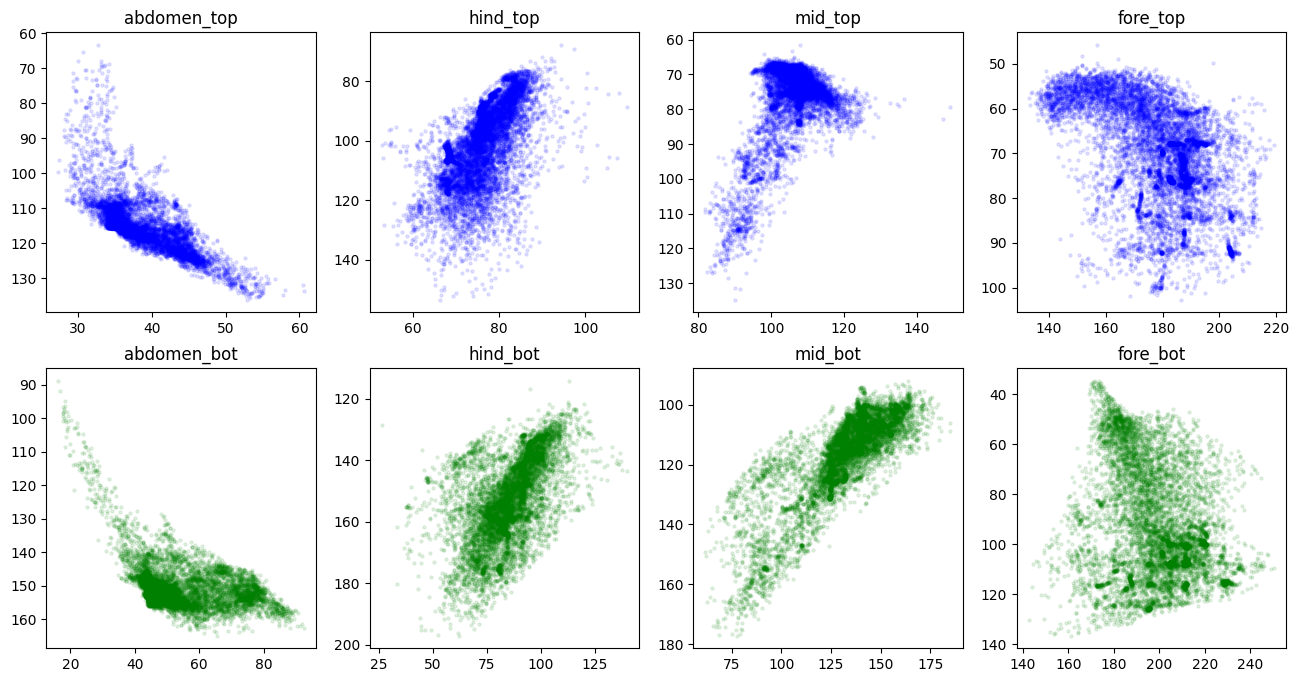

In [5]:
plot_utils.plot_markers(markers[file_ids.index(plot_id)], join_topbot=False)

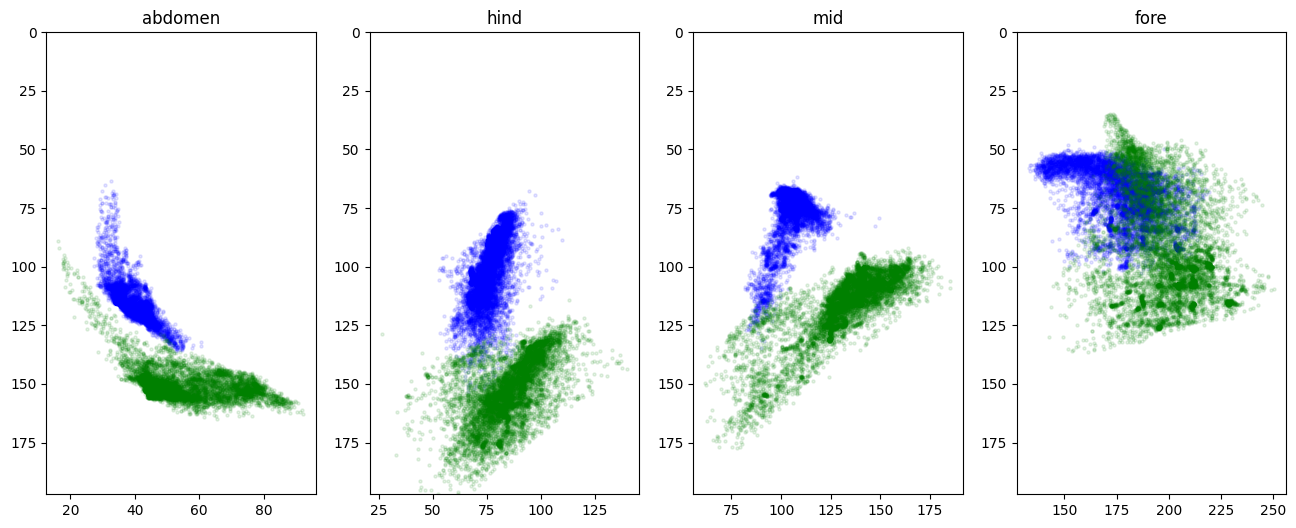

In [18]:
plot_utils.plot_markers(markers[file_ids.index(plot_id)], join_topbot=True)

In [7]:
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]

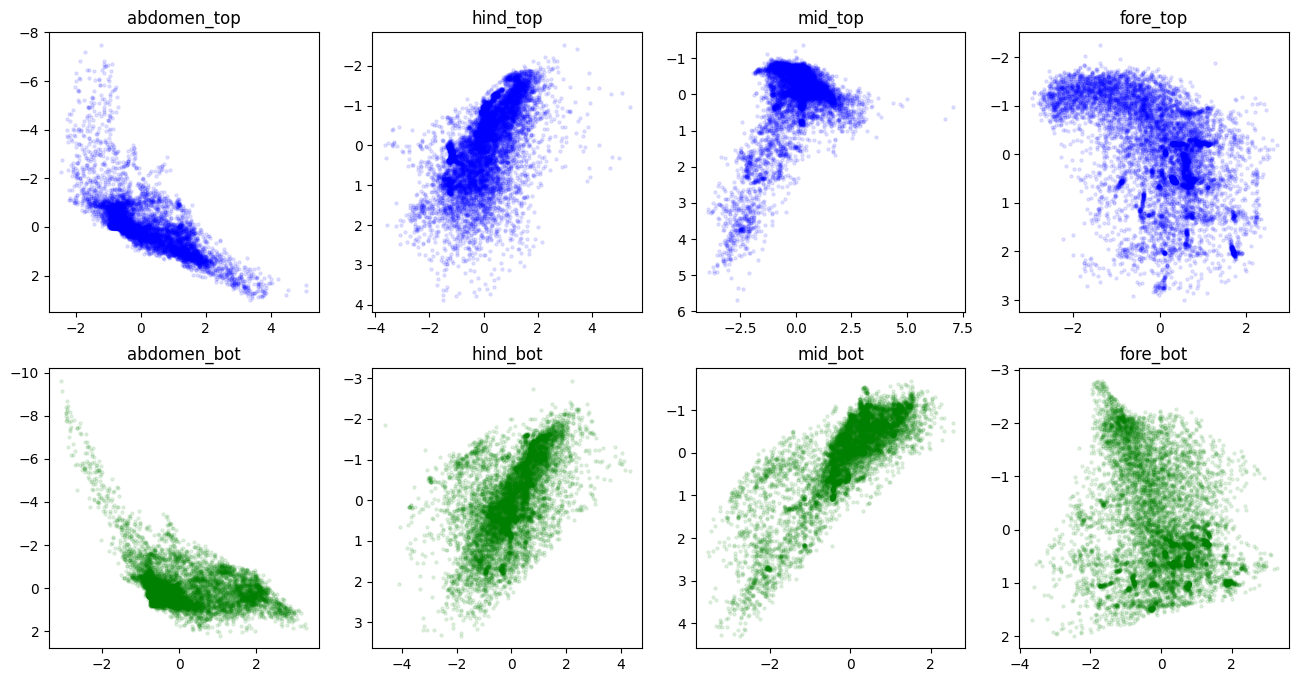

In [8]:
plot_utils.plot_markers(markers_zs[file_ids.index(plot_id)], join_topbot=False)

# PCA raw

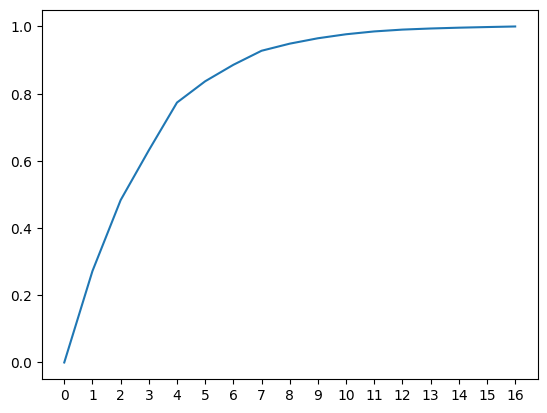

In [9]:
n_pc = 16
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[file_ids.index(plot_id)].values)
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[file_ids.index(plot_id)].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
plt.xticks(range(16+1))
pass

In [10]:
n_pc = 8
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[file_ids.index(plot_id)])
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[file_ids.index(plot_id)].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

# plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
# plt.xticks(range(n_pc+1))
print(np.sum(vars_expl[:vars_expl.shape[0]]))

0.9488697248342737


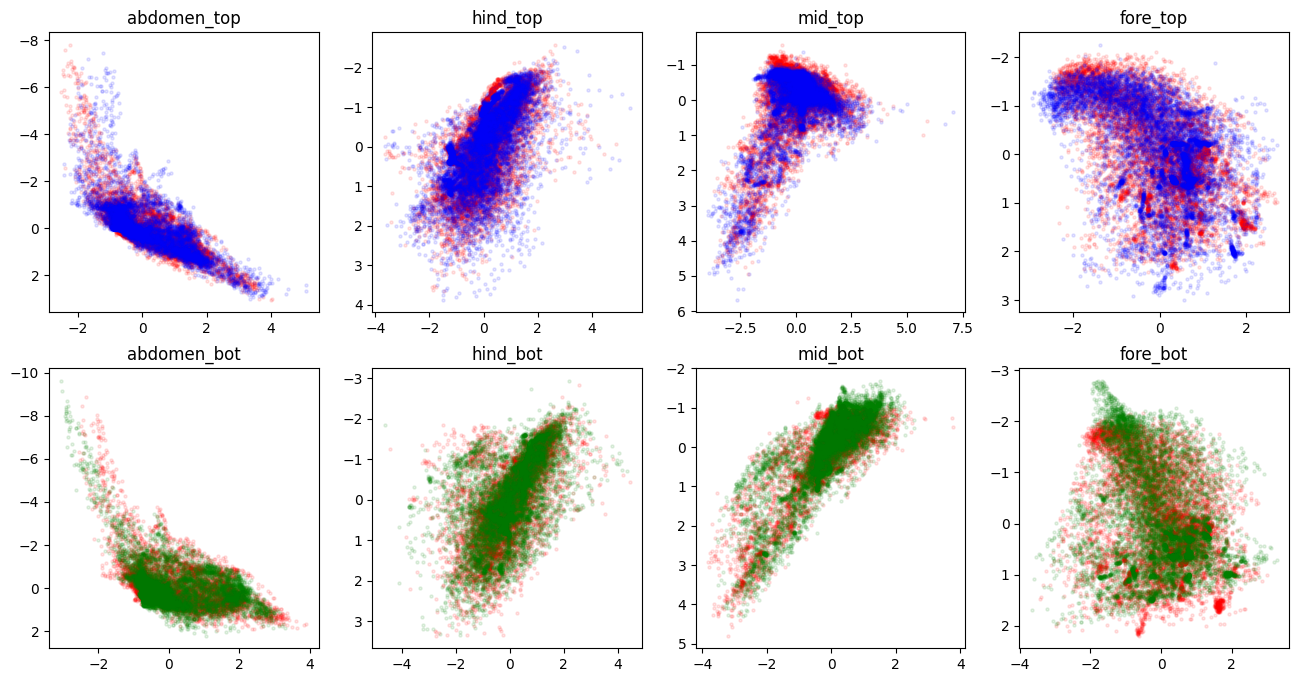

In [11]:
plot_utils.plot_markers(markers_zs[file_ids.index(plot_id)], recon, join_topbot=False)

# grad

In [12]:
markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]
markers_grad_zs = [
	pd.DataFrame(
		data=(marker_grad.values - marker_grad.values.mean(axis=0)) / np.where((marker_std := np.std(marker_grad.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker_grad.columns)
	for marker_grad in markers_grad
]

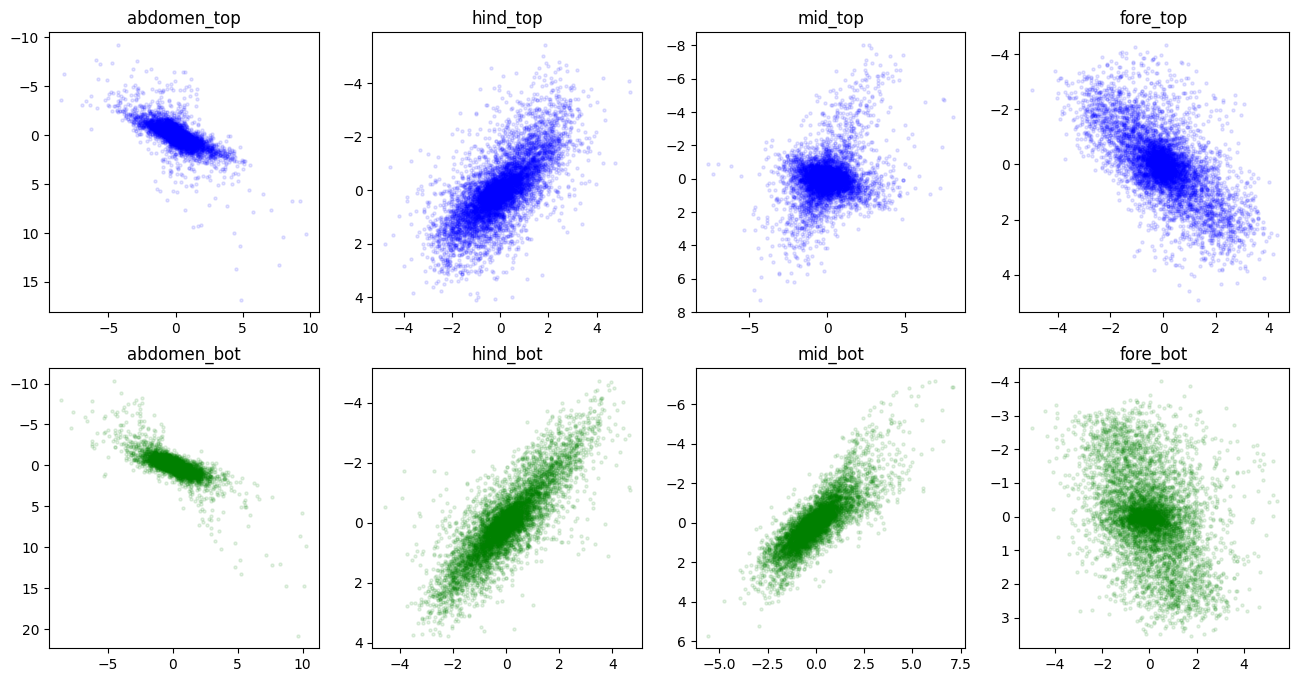

In [13]:
plot_utils.plot_markers(markers_grad_zs[file_ids.index(plot_id)], join_topbot=False)

# ALIGNMENT ACROSS FLIES

In [14]:
from cycler import cycler

In [15]:
def plot_markers_stacked(markers_list, save_path=None):
	fig, axes = plt.subplots(2, 4, figsize=(16, 8), squeeze=False)

	plt.rcParams['axes.prop_cycle'] = cycler(color=plt.cm.tab20.colors)
	colors = iter(plt.rcParams['axes.prop_cycle'].by_key()['color'])

	for markers in markers_list:
		color = next(colors)

		for i in range(4):
			name = markers.columns[i * 4].split('-')[0]

			ax = axes[0, i]
			ax.scatter(markers[f'{name}-top_x'].values, markers[f'{name}-top_y'].values, color=color, alpha=0.05, s=5)

			ax.invert_yaxis()
			ax.set_title(name + '_top')
			ax = axes[1, i]
			ax.scatter(markers[f'{name}-bot_x'].values, markers[f'{name}-bot_y'].values, color=color, alpha=0.05, s=5)
			ax.invert_yaxis()
			ax.set_title(name + '_bot')

		if save_path is not None: plt.savefig(f'{save_path}.png', dpi=300, bbox_inches='tight')

	plt.show()

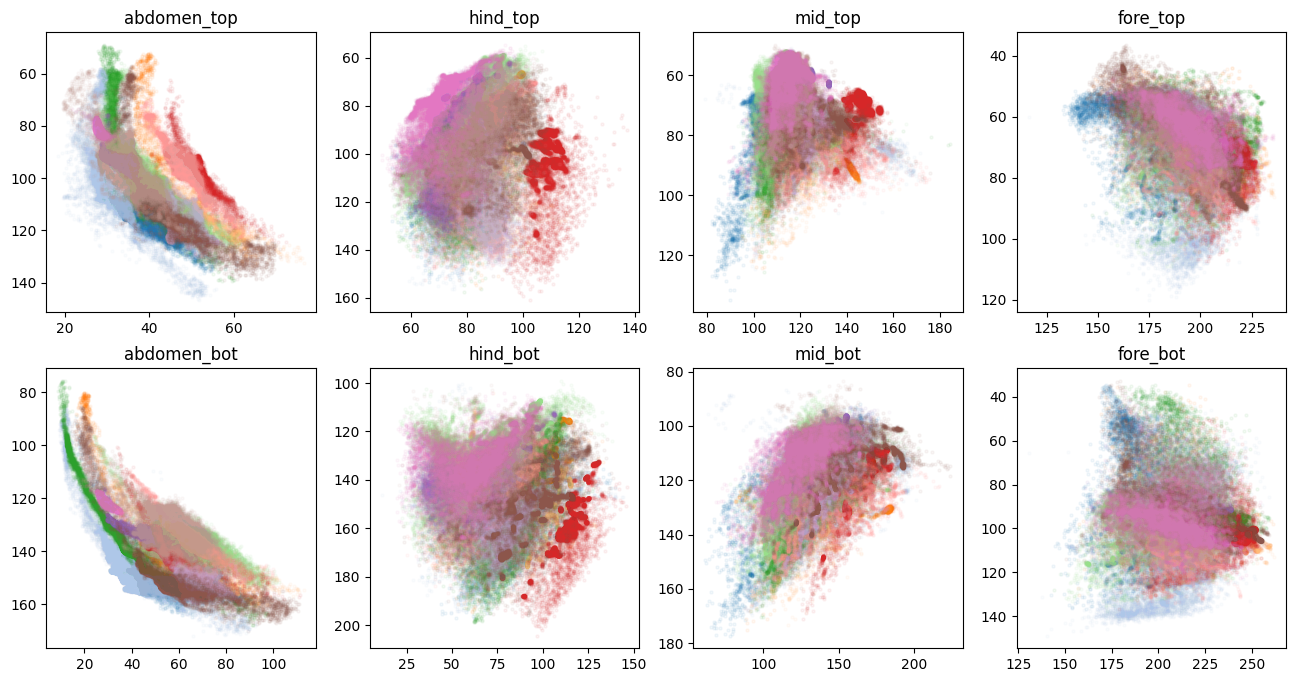

In [16]:
plot_markers_stacked(markers)

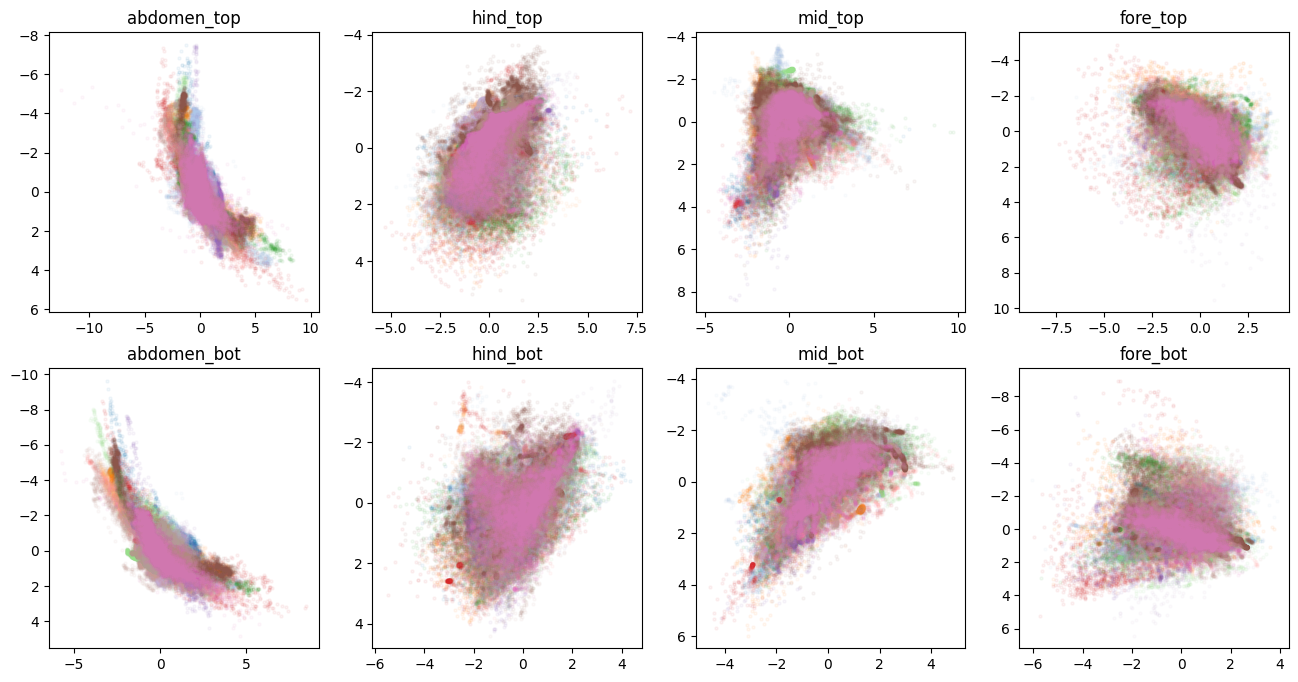

In [17]:
plot_markers_stacked(markers_zs)